# IA102 — Notebook 3 — Réseaux convolutifs et données images

**Durée : 35 minutes** · Objectifs visés : **O2** (créer des réseaux), **O3** (entraîner avec PyTorch), **O4** (utiliser un GPU)

On entraîne un **réseau convolutif** (CNN) à reconnaître 10 catégories de vêtements à partir de 60 000 images en niveaux de gris.

### Plan
1. Le jeu de données FashionMNIST
2. Les limites des réseaux entièrement connectés pour les images
3. La convolution
4. Le sous-échantillonnage (pooling)
5. `Dataset` et `DataLoader` : l'entraînement par mini-lots
6. Architecture du CNN
7. Entraînement sur GPU ou CPU
8. Analyse des erreurs
9. Exercice : un réseau plus profond

In [1]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [2]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
torch.manual_seed(0)

# Les nœuds de calcul de l'Alliance n'ont pas accès à Internet : téléchargez les données au préalable
# avec preparer_donnees.py (sur un nœud de connexion) et indiquez leur dossier dans IA102_DONNEES.
DOSSIER_DONNEES = os.environ.get("IA102_DONNEES", "donnees")
appareil = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil de calcul :", appareil)

Appareil de calcul : cpu


## 1. Le jeu de données FashionMNIST

70 000 images de 28 × 28 pixels (60 000 pour l'entraînement, 10 000 pour le test), réparties en 10 classes. `transforms.ToTensor()` convertit chaque image en tenseur de forme (1, 28, 28), à valeurs dans [0, 1].

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 278kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.09MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.9MB/s]


Entraînement : 60000 images | Test : 10000 images
Forme d'une image : (1, 28, 28) | étiquette : 9 -> Bottine


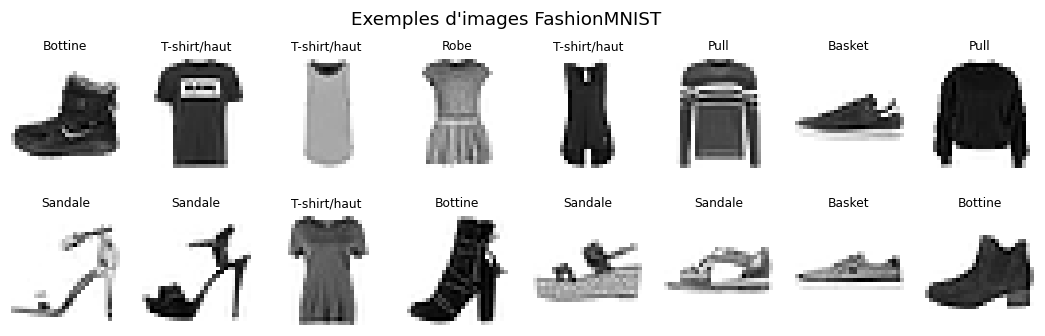

In [3]:
transformation = transforms.ToTensor()
donnees_ent = datasets.FashionMNIST(DOSSIER_DONNEES, train=True, download=True, transform=transformation)
donnees_test = datasets.FashionMNIST(DOSSIER_DONNEES, train=False, download=True, transform=transformation)
CLASSES = ["T-shirt/haut", "Pantalon", "Pull", "Robe", "Manteau", "Sandale", "Chemise", "Basket", "Sac", "Bottine"]
print(f"Entraînement : {len(donnees_ent)} images | Test : {len(donnees_test)} images")

image, etiquette = donnees_ent[0]
print("Forme d'une image :", tuple(image.shape), "| étiquette :", etiquette, "->", CLASSES[etiquette])

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.ravel(), range(16)):
    img, lab = donnees_ent[i]
    ax.imshow(img[0], cmap="gray_r"); ax.set_title(CLASSES[lab], fontsize=8); ax.axis("off")
plt.suptitle("Exemples d'images FashionMNIST"); plt.show()

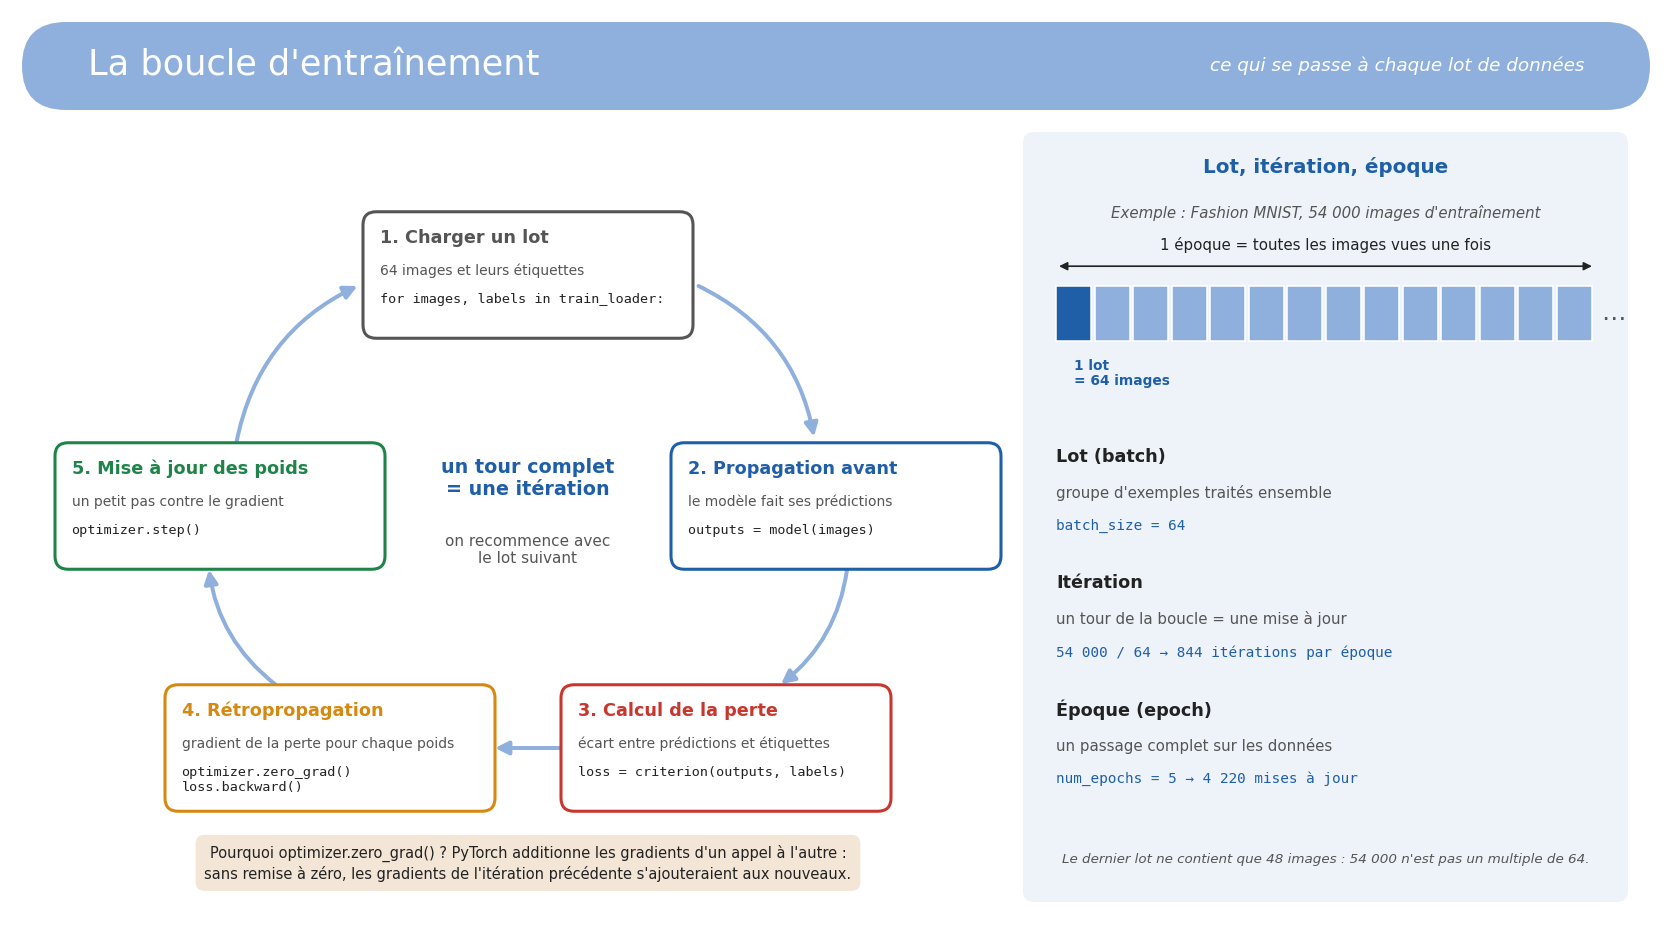

In [ ]:
# @title
import math
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

# Couleurs de la charte des figures
ENCRE, GRIS = "#222222", "#555555"
BLEU, BLEU_CLAIR, FOND = "#1f5fa8", "#8fb0dd", "#eef3fa"
ROUGE, VERT, ORANGE, BEIGE = "#c8372d", "#1e8449", "#d68910", "#f4e6d7"


def milliers(n):
    """Entier avec une espace comme séparateur de milliers : 54000 → 54 000."""
    return f"{n:,}".replace(",", " ")


def fleche(ax, depart, arrivee, rad=0.0):
    ax.add_patch(FancyArrowPatch(depart, arrivee, arrowstyle="-|>", mutation_scale=18, color=BLEU_CLAIR,
                                 lw=2.6, shrinkA=0, shrinkB=0, zorder=2, connectionstyle=f"arc3,rad={rad}"))


def boite(ax, x, y, l, h, couleur):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1.2",
                                fc="white", ec=couleur, lw=2, zorder=3))


def encadre(ax, x, y, l, h):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1",
                                fc=FOND, ec="none", zorder=1))


# Réglages de l'entraînement (Fashion MNIST) : les chiffres de la figure en découlent
n_images, batch_size, num_epochs = 54_000, 64, 5
lots_par_epoque = math.ceil(n_images / batch_size)          # 844
taille_dernier_lot = n_images - (lots_par_epoque - 1) * batch_size
total_iterations = lots_par_epoque * num_epochs

# Fond de la figure, en coordonnées 0..150 × 0..84
fig = plt.figure(figsize=(15, 8.4))
f = fig.add_axes([0, 0, 1, 1])
f.set_xlim(0, 150); f.set_ylim(0, 84); f.axis("off")
f.add_patch(FancyBboxPatch((1, 75), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
f.text(7, 79, "La boucle d'entraînement", color="white", fontsize=23, va="center")
f.text(143, 79, "ce qui se passe à chaque lot de données", color="white", fontsize=12,
       va="center", ha="right", style="italic")

# Les 5 étapes d'une itération, avec la ligne de code correspondante
etapes = [
    ("1. Charger un lot", f"{batch_size} images et leurs étiquettes", "for images, labels in train_loader:", GRIS),
    ("2. Propagation avant", "le modèle fait ses prédictions", "outputs = model(images)", BLEU),
    ("3. Calcul de la perte", "écart entre prédictions et étiquettes", "loss = criterion(outputs, labels)", ROUGE),
    ("4. Rétropropagation", "gradient de la perte pour chaque poids", "optimizer.zero_grad()\nloss.backward()", ORANGE),
    ("5. Mise à jour des poids", "un petit pas contre le gradient", "optimizer.step()", VERT),
]
cx, cy = 47, 39
centres = [(47, 60), (75, 39), (65, 17), (29, 17), (19, 39)]
L, H = 30, 11.5
for (x, y), (titre, detail, ligne, c) in zip(centres, etapes):
    boite(f, x - L / 2, y - H / 2, L, H, c)
    f.text(x - L / 2 + 1.5, y + 3.4, titre, fontsize=11.5, fontweight="bold", color=c, va="center")
    f.text(x - L / 2 + 1.5, y + .4, detail, fontsize=9.1, color=GRIS, va="center")
    f.text(x - L / 2 + 1.5, y - 1.6, ligne, fontsize=8.8, family="monospace", color=ENCRE, va="top", linespacing=1.2)

# Flèches entre les étapes, dans le sens horaire
for dep, arr, rad in (((62.5, 59), (73, 45.3), -.25), ((76, 33.2), (70, 22.8), -.2), ((50, 17), (44, 17), 0),
                      ((24, 22.8), (18, 33.2), -.2), ((20.5, 44.8), (31.5, 59), -.25)):
    fleche(f, dep, arr, rad=rad)

f.text(cx, cy + 2.5, "un tour complet\n= une itération", ha="center", va="center", fontsize=12.5,
       fontweight="bold", color=BLEU, linespacing=1.2)
f.text(cx, cy - 4, "on recommence avec\nle lot suivant", ha="center", va="center", fontsize=10, color=GRIS, linespacing=1.2)

# Panneau de droite : lots, itérations, époques (Fashion MNIST)
x0 = 92
encadre(f, x0, 3, 55, 70)
f.text(x0 + 27.5, 69.3, "Lot, itération, époque", ha="center", fontsize=13, fontweight="bold", color=BLEU)
f.text(x0 + 27.5, 65.2, f"Exemple : Fashion MNIST, {milliers(n_images)} images d'entraînement", ha="center", fontsize=9.8, color=GRIS, style="italic")

# Bande de données découpée en lots
by, bh = 54, 5
n_aff = 14
for i in range(n_aff):
    xx = x0 + 3 + i * 3.5
    f.add_patch(plt.Rectangle((xx, by), 3.2, bh, fc=BLEU if i == 0 else BLEU_CLAIR, ec="white", lw=1, zorder=3))
f.text(x0 + 3 + n_aff * 3.5 + .6, by + bh / 2, "…", fontsize=16, va="center", color=GRIS)
f.text(x0 + 4.6, by - 1.6, f"1 lot\n= {batch_size} images", fontsize=9, color=BLEU, va="top", fontweight="bold", linespacing=1.1)
f.add_patch(FancyArrowPatch((x0 + 3, by + bh + 1.8), (x0 + 52, by + bh + 1.8), arrowstyle="<|-|>", mutation_scale=11, color=ENCRE, lw=1.1))
f.text(x0 + 27.5, by + bh + 3.3, "1 époque = toutes les images vues une fois", ha="center", fontsize=9.8, color=ENCRE)

defs = [("Lot (batch)", "groupe d'exemples traités ensemble", f"batch_size = {batch_size}"),
        ("Itération", "un tour de la boucle = une mise à jour",
         f"{milliers(n_images)} / {batch_size} → {milliers(lots_par_epoque)} itérations par époque"),
        ("Époque (epoch)", "un passage complet sur les données",
         f"num_epochs = {num_epochs} → {milliers(total_iterations)} mises à jour")]
for i, (terme, sens, exemple) in enumerate(defs):
    yy = 43.5 - i * 11.5
    f.text(x0 + 3, yy, terme, fontsize=11.5, fontweight="bold", color=ENCRE, va="center")
    f.text(x0 + 3, yy - 3.3, sens, fontsize=9.8, color=GRIS, va="center")
    f.text(x0 + 3, yy - 6.3, exemple, fontsize=9.4, family="monospace", color=BLEU, va="center")
if taille_dernier_lot < batch_size:
    f.text(x0 + 27.5, 6.5, f"Le dernier lot ne contient que {taille_dernier_lot} images : "
                           f"{milliers(n_images)} n'est pas un multiple de {batch_size}.",
           ha="center", fontsize=8.8, color=GRIS, style="italic")

# Rappel sous la boucle
f.text(47, 6.5, "Pourquoi optimizer.zero_grad() ? PyTorch additionne les gradients d'un appel à l'autre :\n"
                "sans remise à zéro, les gradients de l'itération précédente s'ajouteraient aux nouveaux.",
       ha="center", va="center", fontsize=9.6, color=ENCRE, linespacing=1.3,
       bbox=dict(boxstyle="round,pad=.6", fc=BEIGE, ec="none"))
plt.savefig("fig4_entrainement.png", dpi=170, facecolor="white")
plt.show()

## 2. Les limites des réseaux entièrement connectés pour les images

On pourrait aplatir chaque image en un vecteur de 784 valeurs et utiliser le réseau du notebook 2. Deux difficultés apparaissent :

1. **Nombre de paramètres.** Pour une photographie couleur de 224 × 224 pixels, une seule couche de 512 neurones requiert 224 × 224 × 3 × 512 ≈ **77 millions** de poids.
2. **Perte de la structure spatiale.** Une fois l'image aplatie, la notion de pixels voisins disparaît. Un motif décalé de deux pixels active des poids complètement différents.

Le réseau convolutif répond à ces deux difficultés grâce à la **connectivité locale** et au **partage des poids**.

## 3. La convolution

Un **filtre** (ou noyau) est une petite matrice de poids, par exemple 3 × 3, que l'on fait glisser sur l'image. À chaque position, on calcule la somme des produits entre le filtre et les pixels recouverts :

$$S(i, j) = \sum_{u=-1}^{1} \sum_{v=-1}^{1} K(u, v)\, I(i + u,\, j + v) + b$$

Le résultat est une **carte de caractéristiques**, qui prend de fortes valeurs là où le motif recherché est présent. Le même filtre est appliqué partout : 9 poids suffisent pour détecter un motif quelle que soit sa position.

Appliquons des filtres définis à la main :

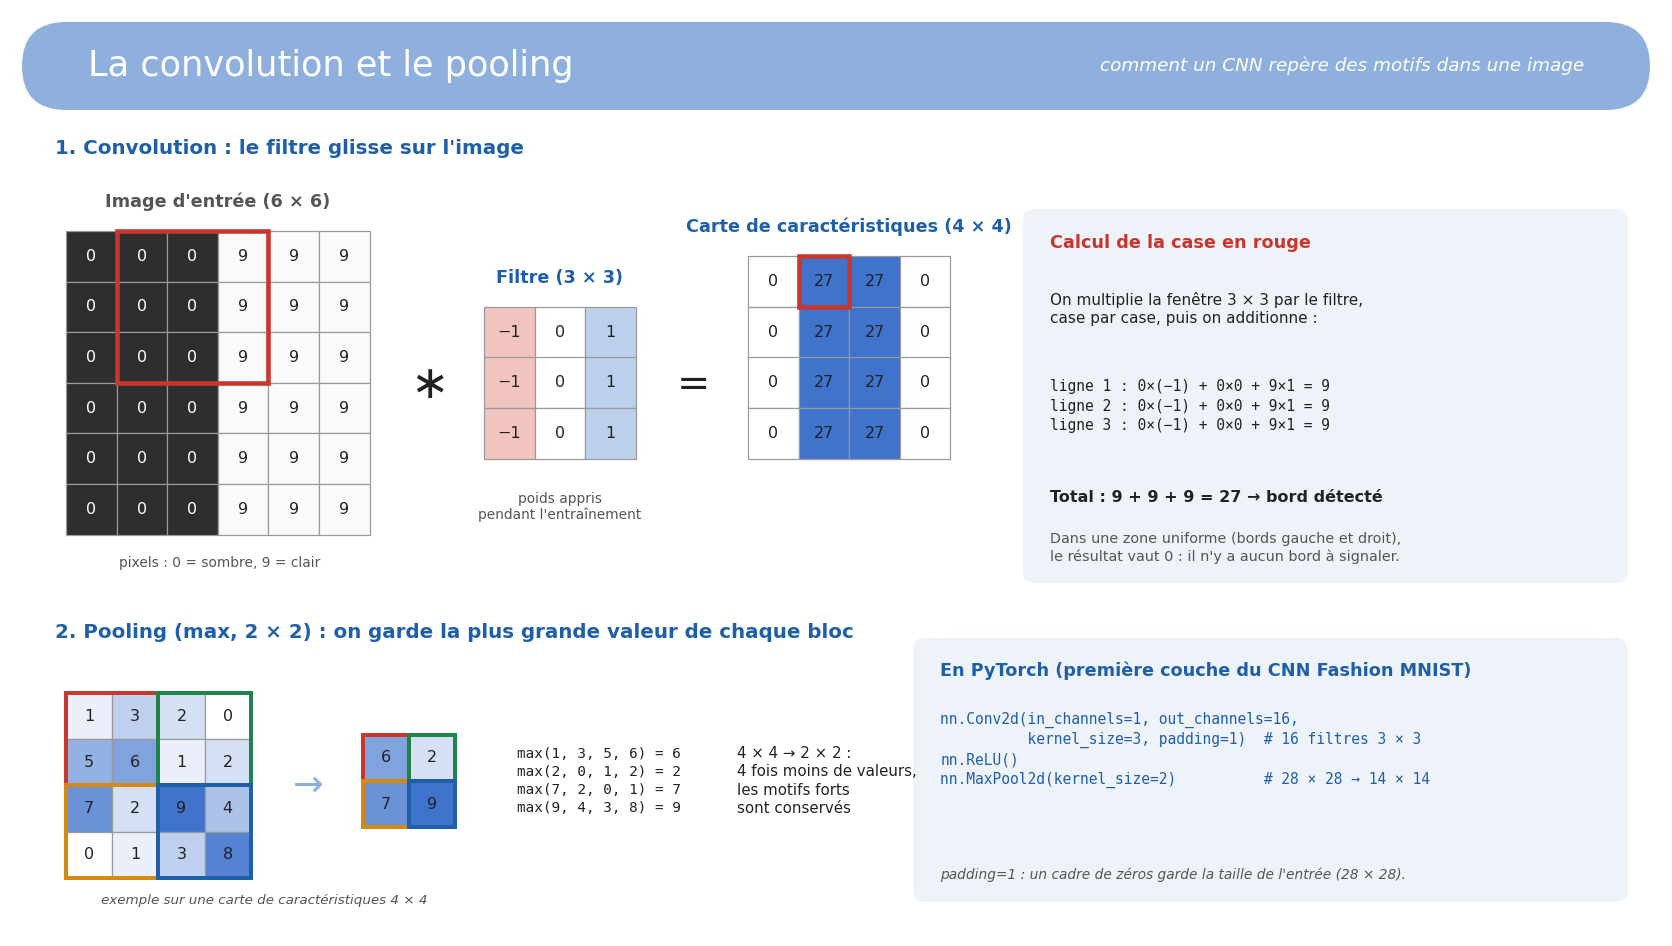

In [ ]:
# @title
# @ title
from matplotlib.patches import FancyBboxPatch

# Couleurs de la charte des figures
ENCRE, GRIS = "#222222", "#555555"
BLEU, BLEU_CLAIR, FOND = "#1f5fa8", "#8fb0dd", "#eef3fa"
ROUGE, VERT, ORANGE = "#c8372d", "#1e8449", "#d68910"


def nombre(v, dec=0):
    """Nombre au format français : virgule décimale et vrai signe moins."""
    return f"{v:.{dec}f}".replace(".", ",").replace("-", "−")


def encadre(ax, x, y, l, h):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1",
                                fc=FOND, ec="none", zorder=1))


# Image 6 × 6 : zone sombre à gauche (0), claire à droite (9), donc un bord vertical
image = np.array([[0, 0, 0, 9, 9, 9]] * 6)
filtre = np.array([[-1, 0, 1]] * 3)       # détecteur de bord vertical (sombre → clair)

# Convolution : le filtre glisse sur l'image, sans cadre de zéros (6 − 3 + 1 = 4)
carte = np.array([[np.sum(image[i:i + 3, j:j + 3] * filtre) for j in range(4)] for i in range(4)])

# Fond de la figure, en coordonnées 0..150 × 0..84
fig = plt.figure(figsize=(15, 8.4))
f = fig.add_axes([0, 0, 1, 1])
f.set_xlim(0, 150); f.set_ylim(0, 84); f.axis("off")
f.add_patch(FancyBboxPatch((1, 75), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
f.text(7, 79, "La convolution et le pooling", color="white", fontsize=23, va="center")
f.text(143, 79, "comment un CNN repère des motifs dans une image", color="white", fontsize=12,
       va="center", ha="right", style="italic")


def grille(x0, y0, M, c=4.6, titre="", couleur=GRIS, surligne=None, cmap=None, vmax=None, fmt=lambda v: str(int(v))):
    """Dessine une matrice case par case ; (x0, y0) est le coin en haut à gauche."""
    n, m = M.shape
    vmax = vmax or max(abs(M).max(), 1)
    for i in range(n):
        for j in range(m):
            v = M[i, j]
            if cmap == "gris":
                fc = str(.18 + .8 * v / vmax)
            elif cmap == "filtre":
                fc = {1: "#bcd0ec", 0: "white", -1: "#f2c4bf"}[int(v)]
            elif cmap == "bleu":
                t = abs(v) / vmax
                fc = (1 - .75 * t, 1 - .55 * t, 1 - .2 * t)
            else:
                fc = "white"
            f.add_patch(plt.Rectangle((x0 + j * c, y0 - (i + 1) * c), c, c, fc=fc, ec="#999999", lw=.8, zorder=3))
            dark = cmap == "gris" and v < vmax * .45
            f.text(x0 + j * c + c / 2, y0 - (i + .5) * c, fmt(v), ha="center", va="center", fontsize=10.5,
                   color="white" if dark else ENCRE, zorder=4)
    if surligne:
        (i0, j0, h, w, col) = surligne
        f.add_patch(plt.Rectangle((x0 + j0 * c, y0 - (i0 + h) * c), w * c, h * c, fc="none", ec=col, lw=3, zorder=5))
    if titre:
        f.text(x0 + m * c / 2, y0 + 2.2, titre, ha="center", fontsize=11.5, fontweight="bold", color=couleur)


# Ligne 1 : convolution
f.text(4, 71, "1. Convolution : le filtre glisse sur l'image", fontsize=13, fontweight="bold", color=BLEU)
grille(5, 64, image, titre="Image d'entrée (6 × 6)", cmap="gris", surligne=(0, 1, 3, 3, ROUGE))
f.text(19, 33.5, "pixels : 0 = sombre, 9 = clair", ha="center", fontsize=9, color=GRIS)
f.text(38, 50, "∗", fontsize=30, ha="center", va="center", color=ENCRE)
grille(43, 57.1, filtre, titre="Filtre (3 × 3)", cmap="filtre", couleur=BLEU, fmt=nombre)
f.text(49.9, 40.3, "poids appris\npendant l'entraînement", ha="center", va="top", fontsize=9, color=GRIS, linespacing=1.15)
f.text(62, 50, "=", fontsize=26, ha="center", va="center", color=ENCRE)
grille(67, 61.7, carte, titre="Carte de caractéristiques (4 × 4)", cmap="bleu", couleur=BLEU,
       surligne=(0, 1, 1, 1, ROUGE), fmt=lambda v: nombre(v, 0))

# Calcul de la case surlignée
encadre(f, 92, 32, 55, 34)
f.text(94.5, 62.5, "Calcul de la case en rouge", fontsize=11.5, fontweight="bold", color=ROUGE)
f.text(94.5, 58.5, "On multiplie la fenêtre 3 × 3 par le filtre,\ncase par case, puis on additionne :", fontsize=10, color=ENCRE, va="top", linespacing=1.25)
fenetre = image[0:3, 1:4]                 # fenêtre sous la case rouge (ligne 0, colonne 1)
lignes = []
for k in range(3):
    termes = " + ".join(f"{p}×{'(' + nombre(q) + ')' if q < 0 else q}" for p, q in zip(fenetre[k], filtre[k]))
    lignes.append(f"ligne {k + 1} : {termes} = {np.sum(fenetre[k] * filtre[k])}")
f.text(94.5, 50.5, "\n".join(lignes), fontsize=9.6, family="monospace", color=ENCRE, va="top", linespacing=1.35)
sommes = [int(np.sum(fenetre[k] * filtre[k])) for k in range(3)]
f.text(94.5, 40.5, f"Total : {' + '.join(map(str, sommes))} = {carte[0, 1]} → bord détecté",
       fontsize=10.5, fontweight="bold", color=ENCRE, va="top")
f.text(94.5, 36.6, "Dans une zone uniforme (bords gauche et droit),\nle résultat vaut 0 : il n'y a aucun bord à signaler.",
       fontsize=9.4, color=GRIS, va="top", linespacing=1.25)

# Ligne 2 : max pooling 2 × 2 sur une autre carte, aux valeurs variées
f.text(4, 27, "2. Pooling (max, 2 × 2) : on garde la plus grande valeur de chaque bloc", fontsize=13, fontweight="bold", color=BLEU)
ex = np.array([[1, 3, 2, 0], [5, 6, 1, 2], [7, 2, 9, 4], [0, 1, 3, 8]])
grille(5, 22, ex, c=4.2, cmap="bleu", vmax=9)
blocs = ((0, 0, ROUGE), (0, 2, VERT), (2, 0, ORANGE), (2, 2, BLEU))
for (i0, j0, col) in blocs:
    f.add_patch(plt.Rectangle((5 + j0 * 4.2, 22 - (i0 + 2) * 4.2), 8.4, 8.4, fc="none", ec=col, lw=2.6, zorder=5))
f.text(27, 13.6, "→", fontsize=24, ha="center", va="center", color=BLEU_CLAIR)
res = np.array([[ex[2*i:2*i+2, 2*j:2*j+2].max() for j in range(2)] for i in range(2)])
grille(32, 18.2, res, c=4.2, cmap="bleu", vmax=9)
for (i0, j0, col) in blocs:
    f.add_patch(plt.Rectangle((32 + j0 // 2 * 4.2, 18.2 - (i0 // 2 + 1) * 4.2), 4.2, 4.2, fc="none", ec=col, lw=2.6, zorder=5))
f.text(23, 2.8, "exemple sur une carte de caractéristiques 4 × 4", ha="center", fontsize=8.8, color=GRIS, style="italic")
calculs = [f"max({', '.join(map(str, ex[i0:i0 + 2, j0:j0 + 2].ravel()))}) = {ex[i0:i0 + 2, j0:j0 + 2].max()}"
           for (i0, j0, _) in blocs]
f.text(46, 14, "\n".join(calculs), fontsize=9.4, family="monospace", color=ENCRE, va="center", linespacing=1.35)
f.text(66, 14, "4 × 4 → 2 × 2 :\n4 fois moins de valeurs,\nles motifs forts\nsont conservés", fontsize=9.8, color=ENCRE, va="center", linespacing=1.3)

# Encadré : en PyTorch
encadre(f, 82, 3, 65, 24)
f.text(84.5, 23.5, "En PyTorch (première couche du CNN Fashion MNIST)", fontsize=11.5, fontweight="bold", color=BLEU)
f.text(84.5, 20.3, "nn.Conv2d(in_channels=1, out_channels=16,\n"
                    "          kernel_size=3, padding=1)  # 16 filtres 3 × 3\n"
                    "nn.ReLU()\n"
                    "nn.MaxPool2d(kernel_size=2)          # 28 × 28 → 14 × 14",
       family="monospace", fontsize=9.6, color=BLEU, va="top", linespacing=1.35)
f.text(84.5, 5.5, "padding=1 : un cadre de zéros garde la taille de l'entrée (28 × 28).",
       fontsize=9, color=GRIS, style="italic", va="center")
plt.savefig("fig6_convolution.png", dpi=170, facecolor="white")
plt.show()

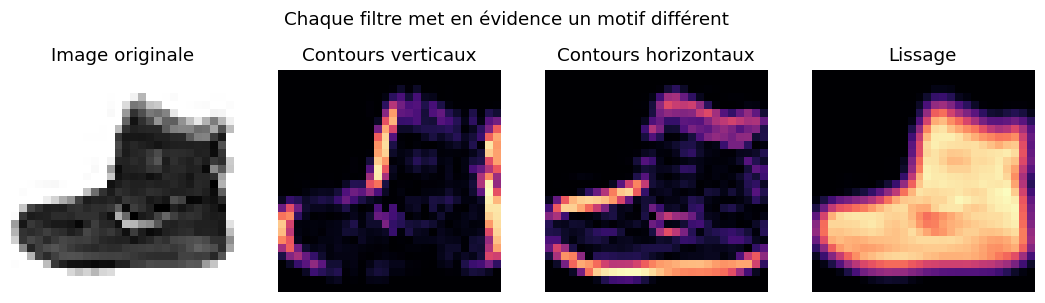

In [ ]:
bottine = donnees_ent[0][0].unsqueeze(0)          # forme (1, 1, 28, 28)
filtres = {
    "Contours verticaux":   [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    "Contours horizontaux": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
    "Lissage":              [[1 / 9] * 3] * 3,
}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
axes[0].imshow(bottine[0, 0], cmap="gray_r"); axes[0].set_title("Image originale")
for ax, (nom, noyau) in zip(axes[1:], filtres.items()):
    noyau = torch.tensor(noyau, dtype=torch.float32).view(1, 1, 3, 3)
    ax.imshow(F.conv2d(bottine, noyau, padding=1)[0, 0].abs(), cmap="magma"); ax.set_title(nom)
for ax in axes: ax.axis("off")
plt.suptitle("Chaque filtre met en évidence un motif différent"); plt.show()

Dans un CNN, les filtres **ne sont pas définis à la main** : leurs poids sont des paramètres appris par descente de gradient, comme ceux d'une couche linéaire.

### Exercice 6 — Concevoir un filtre

Définissez un filtre 3 × 3 (par exemple un filtre de rehaussement des détails, ou un détecteur de diagonales) et appliquez-le à une autre image.

In [ ]:
noyau_perso = [[..., ..., ...],
               [..., ..., ...],
               [..., ..., ...]]   # À COMPLÉTER avec des chiffres

img = donnees_ent[1][0].unsqueeze(0)
carte = F.conv2d(img, torch.tensor(noyau_perso, dtype=torch.float32).view(1, 1, 3, 3), padding=1)
fig, (a, b) = plt.subplots(1, 2, figsize=(6, 3))
a.imshow(img[0, 0], cmap="gray_r"); a.set_title(CLASSES[donnees_ent[1][1]]); a.axis("off")
b.imshow(carte[0, 0].abs(), cmap="magma"); b.set_title("Carte de caractéristiques"); b.axis("off"); plt.show()

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
noyau_perso = [[ 0, -1,  0],
               [-1,  5, -1],
               [ 0, -1,  0]]   # rehaussement des détails

img = donnees_ent[1][0].unsqueeze(0)
carte = F.conv2d(img, torch.tensor(noyau_perso, dtype=torch.float32).view(1, 1, 3, 3), padding=1)
fig, (a, b) = plt.subplots(1, 2, figsize=(6, 3))
a.imshow(img[0, 0], cmap="gray_r"); a.set_title(CLASSES[donnees_ent[1][1]]); a.axis("off")
b.imshow(carte[0, 0].abs(), cmap="magma"); b.set_title("Carte de caractéristiques"); b.axis("off"); plt.show()
```

</details>

## 4. Le sous-échantillonnage (pooling)

Le **max pooling** 2 × 2 divise la carte en blocs de 4 valeurs et conserve le maximum de chacun. La taille est divisée par deux dans chaque direction ; l'information « le motif est présent dans cette zone » est conservée, avec une tolérance aux petits décalages.

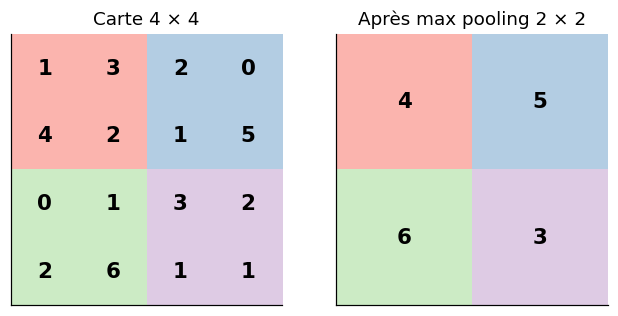

In [ ]:
carte = torch.tensor([[1., 3., 2., 0.], [4., 2., 1., 5.], [0., 1., 3., 2.], [2., 6., 1., 1.]])
resume = F.max_pool2d(carte.view(1, 1, 4, 4), kernel_size=2)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
couleurs = np.array([[0, 0, 1, 1], [0, 0, 1, 1], [2, 2, 3, 3], [2, 2, 3, 3]])
for ax, m, coul, titre in [(axes[0], carte, couleurs, "Carte 4 × 4"), (axes[1], resume[0, 0], np.array([[0, 1], [2, 3]]), "Après max pooling 2 × 2")]:
    ax.imshow(coul, cmap="Pastel1", vmin=0, vmax=8)
    for (i, j), v in np.ndenumerate(m.numpy()):
        ax.text(j, i, int(v), ha="center", va="center", fontsize=14, fontweight="bold")
    ax.set_title(titre); ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 5. `Dataset` et `DataLoader` : l'entraînement par mini-lots

On ne présente ni l'ensemble des 60 000 images à la fois (mémoire insuffisante), ni une image à la fois (calcul inefficace). On utilise des **mini-lots**, par exemple de 64 images : une mise à jour des paramètres par lot. C'est la **descente de gradient stochastique par mini-lots**.

- Un **`Dataset`** donne accès à une observation par son indice (`dataset[i]` renvoie l'image et son étiquette).
- Un **`DataLoader`** regroupe les observations en lots, les **mélange** à chaque époque (`shuffle=True`) et peut les charger en parallèle (`num_workers`, voir notebook 5).

In [7]:
charge_ent = DataLoader(donnees_ent, batch_size=64, shuffle=True)
charge_test = DataLoader(donnees_test, batch_size=1000)
images, etiquettes = next(iter(charge_ent))
print("Lot d'images :", tuple(images.shape), "-> (lot, canaux, hauteur, largeur)")
print("Lot d'étiquettes :", tuple(etiquettes.shape))
print("Nombre de lots par époque :", len(charge_ent))

Lot d'images : (64, 1, 28, 28) -> (lot, canaux, hauteur, largeur)
Lot d'étiquettes : (64,)
Nombre de lots par époque : 938


Pour des données personnelles (fichiers d'images, tableaux, signaux), on écrit une sous-classe de `Dataset` avec deux méthodes :

```python
class MonJeuDeDonnees(torch.utils.data.Dataset):
    def __init__(self, chemins, etiquettes, transformation=None):
        self.chemins, self.etiquettes, self.transformation = chemins, etiquettes, transformation
    def __len__(self):
        return len(self.chemins)
    def __getitem__(self, i):
        image = Image.open(self.chemins[i])
        if self.transformation:
            image = self.transformation(image)
        return image, self.etiquettes[i]
```

## 6. Architecture du CNN

Deux blocs **convolution → ReLU → max pooling** extraient des caractéristiques ; une petite partie entièrement connectée effectue la classification.

```
Image (1, 28, 28)
 -> Conv 3×3, 16 filtres, ReLU, MaxPool 2×2   -> (16, 14, 14)   motifs simples : contours, coins
 -> Conv 3×3, 32 filtres, ReLU, MaxPool 2×2   -> (32, 7, 7)     motifs composés : col, semelle, manche
 -> Flatten                                    -> 1568 valeurs
 -> Linear 1568 -> 64, ReLU, Linear 64 -> 10   -> un score par classe
```

Plus on progresse dans le réseau, plus les caractéristiques sont abstraites et couvrent une grande zone de l'image (champ récepteur).

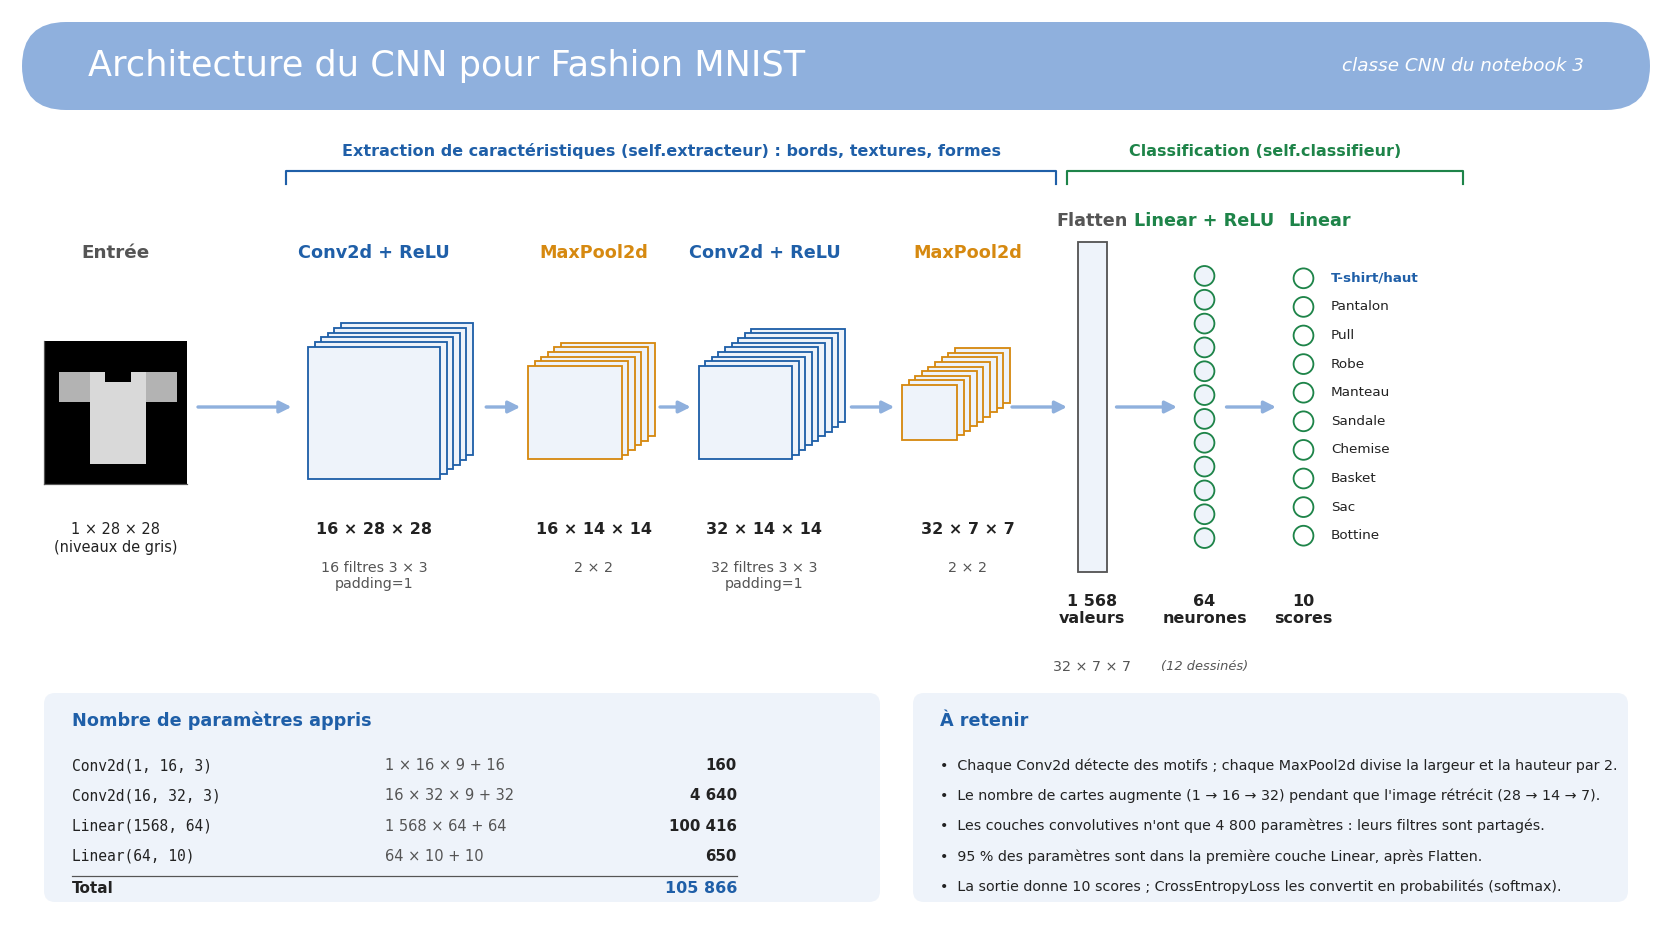

In [ ]:
# @title
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch, Rectangle

# Couleurs de la charte des figures
ENCRE, GRIS = "#222222", "#555555"
BLEU, BLEU_CLAIR, FOND = "#1f5fa8", "#8fb0dd", "#eef3fa"
VERT, ORANGE = "#1e8449", "#d68910"


def milliers(n):
    """Entier avec une espace comme séparateur de milliers : 105866 → 105 866."""
    return f"{n:,}".replace(",", " ")


def fleche(ax, depart, arrivee):
    ax.add_patch(FancyArrowPatch(depart, arrivee, arrowstyle="-|>", mutation_scale=16, color=BLEU_CLAIR,
                                 lw=2.2, shrinkA=0, shrinkB=0, zorder=2))


def encadre(ax, x, y, l, h):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1",
                                fc=FOND, ec="none", zorder=1))


def pile(ax, x, y, cote, n_aff, couleur, dx=.6):
    """Pile de cartes de caractéristiques : des carrés légèrement décalés."""
    for k in range(n_aff)[::-1]:
        ax.add_patch(Rectangle((x + k * dx, y + k * dx * .7), cote, cote, fc=FOND, ec=couleur,
                               lw=1.2, zorder=3 + n_aff - k))


def colonne(ax, x, n, hauteur, couleur, fc="white"):
    """Colonne de neurones (cercles) centrée verticalement sur y = 48."""
    for k in range(n):
        yk = 48 + (k - (n - 1) / 2) * hauteur / n
        ax.add_patch(Circle((x, yk), .9, fc=fc, ec=couleur, lw=1.2, zorder=4))


# Architecture du CNN du notebook 3 (classe CNN)
c1, c2, cachee, n_classes = 16, 32, 64, 10
n_aplati = c2 * 7 * 7                                   # 32 × 7 × 7 = 1568
couches = [  # (nom affiché, calcul affiché, nombre de paramètres)
    (f"Conv2d(1, {c1}, 3)", f"1 × {c1} × 9 + {c1}", 1 * c1 * 9 + c1),
    (f"Conv2d({c1}, {c2}, 3)", f"{c1} × {c2} × 9 + {c2}", c1 * c2 * 9 + c2),
    (f"Linear({n_aplati}, {cachee})", f"{milliers(n_aplati)} × {cachee} + {cachee}", n_aplati * cachee + cachee),
    (f"Linear({cachee}, {n_classes})", f"{cachee} × {n_classes} + {n_classes}", cachee * n_classes + n_classes),
]
total = sum(p for _, _, p in couches)
params_conv = couches[0][2] + couches[1][2]
part_linear1 = couches[2][2] / total

# Fond de la figure, en coordonnées 0..150 × 0..84
fig = plt.figure(figsize=(15, 8.4))
f = fig.add_axes([0, 0, 1, 1])
f.set_xlim(0, 150); f.set_ylim(0, 84); f.axis("off")
f.add_patch(FancyBboxPatch((1, 75), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
f.text(7, 79, "Architecture du CNN pour Fashion MNIST", color="white", fontsize=23, va="center")
f.text(143, 79, "classe CNN du notebook 3", color="white", fontsize=12, va="center", ha="right", style="italic")

# Image d'entrée : un t-shirt stylisé en niveaux de gris (28 × 28)
img = np.zeros((28, 28))
yy, xx = np.mgrid[0:28, 0:28]
img[(yy > 5) & (yy < 24) & (xx > 8) & (xx < 20)] = .85                                  # corps
img[(yy > 5) & (yy < 12) & (((xx > 2) & (xx <= 8)) | ((xx >= 20) & (xx < 26)))] = .7    # manches
img[(yy < 8) & (abs(xx - 14) < 3)] = 0                                                   # encolure
ax_img = fig.add_axes([3 / 150, 41 / 84, 13 / 150, 13 / 84])
ax_img.imshow(img, cmap="gray", vmin=0, vmax=1); ax_img.set_xticks([]); ax_img.set_yticks([])
for bord in ax_img.spines.values():
    bord.set_color(GRIS)
f.text(9.5, 61.5, "Entrée", ha="center", fontsize=12, fontweight="bold", color=GRIS)
f.text(9.5, 37.5, "1 × 28 × 28\n(niveaux de gris)", ha="center", va="top", fontsize=9.5, color=ENCRE, linespacing=1.2)

# Extraction de caractéristiques : deux blocs convolution → ReLU → max pooling
etapes = [  # (x, côté dessiné, nb de cartes dessinées, forme, titre, détail, couleur)
    (27, 12, 6, f"{c1} × 28 × 28", "Conv2d + ReLU", f"{c1} filtres 3 × 3\npadding=1", BLEU),
    (47, 8.5, 6, f"{c1} × 14 × 14", "MaxPool2d", "2 × 2", ORANGE),
    (62.5, 8.5, 9, f"{c2} × 14 × 14", "Conv2d + ReLU", f"{c2} filtres 3 × 3\npadding=1", BLEU),
    (81, 5, 9, f"{c2} × 7 × 7", "MaxPool2d", "2 × 2", ORANGE),
]
for x, cote, n, forme, titre, detail, c in etapes:
    pile(f, x, 47.5 - cote / 2, cote, n, c)
    f.text(x + 6, 61.5, titre, ha="center", fontsize=11.5, fontweight="bold", color=c)
    f.text(x + 6, 37.5, forme, ha="center", va="top", fontsize=10.5, fontweight="bold", color=ENCRE)
    f.text(x + 6, 34, detail, ha="center", va="top", fontsize=9.3, color=GRIS, linespacing=1.2)
for x1, x2 in ((17, 25.5), (43.2, 46.3), (59, 61.8), (76.4, 80.3), (91, 96)):
    fleche(f, (x1, 48), (x2, 48))

# Classification : aplatissement puis couches entièrement connectées
f.add_patch(Rectangle((97, 33), 2.6, 30, fc=FOND, ec=GRIS, lw=1.2, zorder=3))
f.text(98.3, 64.5, "Flatten", ha="center", fontsize=11.5, fontweight="bold", color=GRIS)
f.text(98.3, 31, f"{milliers(n_aplati)}\nvaleurs", ha="center", va="top", fontsize=10.5, fontweight="bold",
       color=ENCRE, linespacing=1.15)
f.text(98.3, 25, f"{c2} × 7 × 7", ha="center", va="top", fontsize=9.3, color=GRIS)
fleche(f, (100.5, 48), (106, 48))
colonne(f, 108.5, 12, 26, VERT, fc=FOND)
f.text(108.5, 64.5, "Linear + ReLU", ha="center", fontsize=11.5, fontweight="bold", color=VERT)
f.text(108.5, 31, f"{cachee}\nneurones", ha="center", va="top", fontsize=10.5, fontweight="bold",
       color=ENCRE, linespacing=1.15)
f.text(108.5, 25, "(12 dessinés)", ha="center", va="top", fontsize=8.5, color=GRIS, style="italic")
fleche(f, (110.5, 48), (115, 48))
colonne(f, 117.5, n_classes, 26, VERT)
f.text(119, 64.5, "Linear", ha="center", fontsize=11.5, fontweight="bold", color=VERT)
f.text(117.5, 31, f"{n_classes}\nscores", ha="center", va="top", fontsize=10.5, fontweight="bold",
       color=ENCRE, linespacing=1.15)
classes = ["T-shirt/haut", "Pantalon", "Pull", "Robe", "Manteau", "Sandale", "Chemise", "Basket", "Sac", "Bottine"]
for k, nom in enumerate(classes):
    yk = 48 + ((9 - k) - 4.5) * 2.6
    f.text(120, yk, nom, fontsize=8.8, va="center", color=BLEU if k == 0 else ENCRE,
           fontweight="bold" if k == 0 else "normal")

# Accolades : les deux parties du modèle, avec les noms des attributs de la classe
for x1, x2, texte, c in ((25, 95, "Extraction de caractéristiques (self.extracteur) : bords, textures, formes", BLEU),
                         (96, 132, "Classification (self.classifieur)", VERT)):
    f.plot([x1, x1, x2, x2], [68.3, 69.5, 69.5, 68.3], color=c, lw=1.4)
    f.text((x1 + x2) / 2, 70.8, texte, ha="center", fontsize=10.5, color=c, fontweight="bold")

# Tableau des paramètres, calculé à partir de l'architecture
encadre(f, 3, 3, 76, 19)
f.text(5.5, 19, "Nombre de paramètres appris", fontsize=11.5, fontweight="bold", color=BLEU)
for i, (nom, calcul, n_params) in enumerate(couches):
    yl = 15.4 - i * 2.75
    f.text(5.5, yl, nom, fontsize=9.6, family="monospace", color=ENCRE, va="center")
    f.text(34, yl, calcul, fontsize=9.6, color=GRIS, va="center")
    f.text(66, yl, milliers(n_params), fontsize=9.8, color=ENCRE, va="center", ha="right", fontweight="bold")
f.plot([5.5, 66], [5.4, 5.4], color=GRIS, lw=.8)
f.text(5.5, 4.2, "Total", fontsize=10, fontweight="bold", color=ENCRE, va="center")
f.text(66, 4.2, milliers(total), fontsize=10.5, fontweight="bold", color=BLEU, va="center", ha="right")

# Points à retenir
encadre(f, 82, 3, 65, 19)
f.text(84.5, 19, "À retenir", fontsize=11.5, fontweight="bold", color=BLEU)
points = ["Chaque Conv2d détecte des motifs ; chaque MaxPool2d divise la largeur et la hauteur par 2.",
          f"Le nombre de cartes augmente (1 → {c1} → {c2}) pendant que l'image rétrécit (28 → 14 → 7).",
          f"Les couches convolutives n'ont que {milliers(params_conv)} paramètres : leurs filtres sont partagés.",
          f"{part_linear1:.0%} des paramètres sont dans la première couche Linear, après Flatten.".replace("%", " %"),
          "La sortie donne 10 scores ; CrossEntropyLoss les convertit en probabilités (softmax)."]
for i, texte in enumerate(points):
    f.text(84.5, 15.4 - i * 2.75, "•  " + texte, fontsize=9.3, color=ENCRE, va="center")

plt.savefig("fig7_cnn.png", dpi=170, facecolor="white")
plt.show()

In [8]:
class CNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.extracteur = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifieur = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.classifieur(self.extracteur(x))

modele = CNN().to(appareil)
print(modele)
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()))

CNN(
  (extracteur): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifieur): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
Nombre de paramètres : 105866


**Prédiction.** Combien de paramètres compterait un réseau entièrement connecté 784 → 512 → 10 ? Plus ou moins que ce CNN ?

<details><summary><b>Afficher la réponse</b></summary>

784 × 512 + 512 + 512 × 10 + 10 = **407 050** paramètres, soit environ quatre fois plus que ce CNN, pour une exactitude généralement inférieure.
</details>

## 7. Entraînement sur GPU ou CPU

Pour calculer sur GPU, **le modèle et les données doivent se trouver sur le même appareil** : on déplace le modèle une fois (`modele.to(appareil)`), puis chaque lot au moment de son utilisation.

### Exercice 7 — Boucle par mini-lots

In [ ]:
def entrainer_une_epoque(modele, chargeur, optimiseur, perte_fn):
    modele.train()
    total = 0.0
    for images, etiquettes in chargeur:
        images, etiquettes = ..., ...      # À COMPLÉTER : transférer le lot vers l'appareil
        sortie = ...                       # À COMPLÉTER : les cinq étapes
        perte = ...
        ...
        ...
        ...
        total += perte.item() * len(images)
    return total / len(chargeur.dataset)

def evaluer(modele, chargeur, perte_fn):
    modele.eval()
    total, correctes = 0.0, 0
    with torch.no_grad():
        for images, etiquettes in chargeur:
            images, etiquettes = images.to(appareil), etiquettes.to(appareil)
            sortie = modele(images)
            total += perte_fn(sortie, etiquettes).item() * len(images)
            correctes += (sortie.argmax(dim=1) == etiquettes).sum().item()
    return total / len(chargeur.dataset), correctes / len(chargeur.dataset)

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
def entrainer_une_epoque(modele, chargeur, optimiseur, perte_fn):
    modele.train()
    total = 0.0
    for images, etiquettes in chargeur:
        images, etiquettes = images.to(appareil), etiquettes.to(appareil)
        sortie = modele(images)
        perte = perte_fn(sortie, etiquettes)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        total += perte.item() * len(images)
    return total / len(chargeur.dataset)

def evaluer(modele, chargeur, perte_fn):
    modele.eval()
    total, correctes = 0.0, 0
    with torch.no_grad():
        for images, etiquettes in chargeur:
            images, etiquettes = images.to(appareil), etiquettes.to(appareil)
            sortie = modele(images)
            total += perte_fn(sortie, etiquettes).item() * len(images)
            correctes += (sortie.argmax(dim=1) == etiquettes).sum().item()
    return total / len(chargeur.dataset), correctes / len(chargeur.dataset)
```

</details>

Entraînement sur **3 époques** : environ une minute sur un processeur, quelques secondes sur un GPU.

In [11]:
torch.manual_seed(0)
modele = CNN().to(appareil)
optimiseur = torch.optim.Adam(modele.parameters(), lr=1e-3)
perte_fn = nn.CrossEntropyLoss()
suivi = {"perte_ent": [], "perte_test": [], "exactitude_test": []}

for epoque in range(1, 4):
    debut = time.time()
    perte_ent = entrainer_une_epoque(modele, charge_ent, optimiseur, perte_fn)
    perte_test, exact_test = evaluer(modele, charge_test, perte_fn)
    suivi["perte_ent"].append(perte_ent); suivi["perte_test"].append(perte_test); suivi["exactitude_test"].append(exact_test)
    print(f"Époque {epoque} | perte entraînement {perte_ent:.3f} | perte test {perte_test:.3f} | "
          f"exactitude test {exact_test:.1%} | {time.time() - debut:.0f} s")

Époque 1 | perte entraînement 0.544 | perte test 0.382 | exactitude test 86.5% | 53 s
Époque 2 | perte entraînement 0.334 | perte test 0.320 | exactitude test 88.7% | 48 s
Époque 3 | perte entraînement 0.286 | perte test 0.302 | exactitude test 89.0% | 46 s


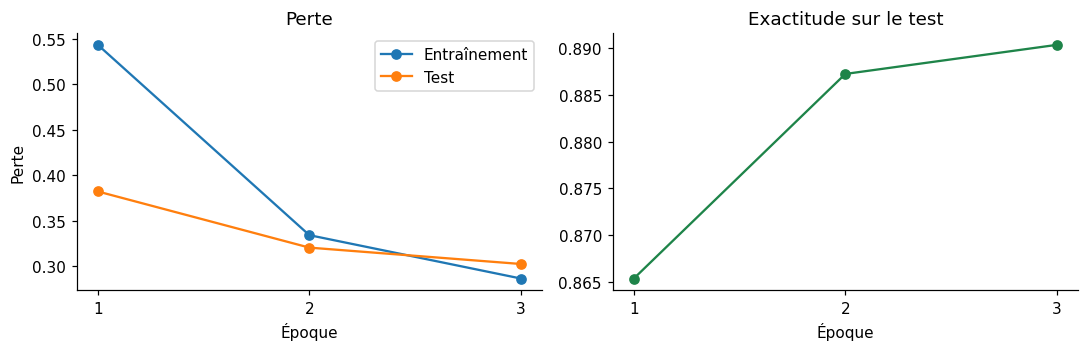

In [12]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.3))
ep = range(1, len(suivi["perte_ent"]) + 1)
a.plot(ep, suivi["perte_ent"], "o-", label="Entraînement"); a.plot(ep, suivi["perte_test"], "o-", label="Test")
a.set_xlabel("Époque"); a.set_ylabel("Perte"); a.set_title("Perte"); a.set_xticks(list(ep)); a.legend()
b.plot(ep, suivi["exactitude_test"], "o-", color="#1e8449"); b.set_xlabel("Époque"); b.set_xticks(list(ep))
b.set_title("Exactitude sur le test"); plt.tight_layout(); plt.show()

## 8. Analyse des erreurs

L'exactitude globale ne révèle pas quelles classes sont confondues. La matrice de confusion (IA101, notebook 3) le montre.

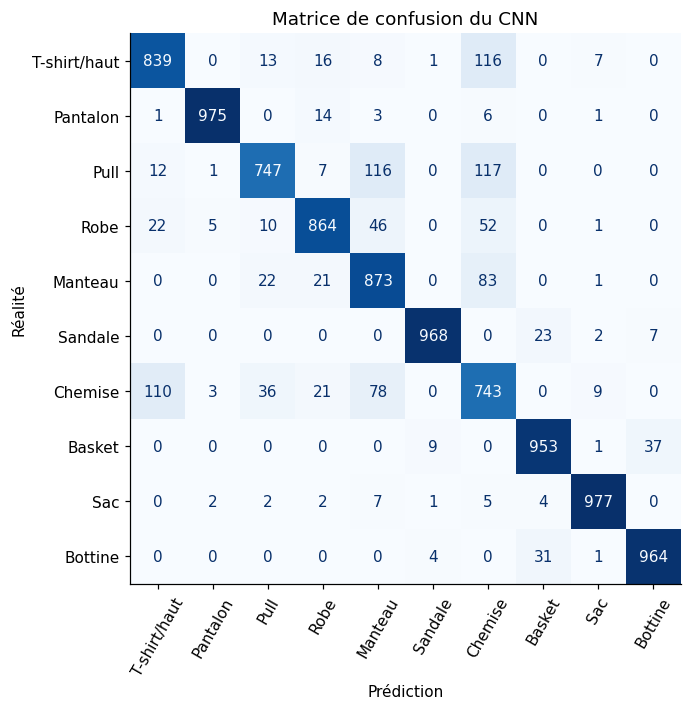

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

modele.eval(); vraies, predites, toutes_images = [], [], []
with torch.no_grad():
    for images, etiquettes in charge_test:
        vraies.append(etiquettes); predites.append(modele(images.to(appareil)).argmax(1).cpu()); toutes_images.append(images)
vraies, predites, toutes_images = torch.cat(vraies), torch.cat(predites), torch.cat(toutes_images)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(confusion_matrix(vraies, predites), display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=60)
ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité"); ax.set_title("Matrice de confusion du CNN"); plt.show()

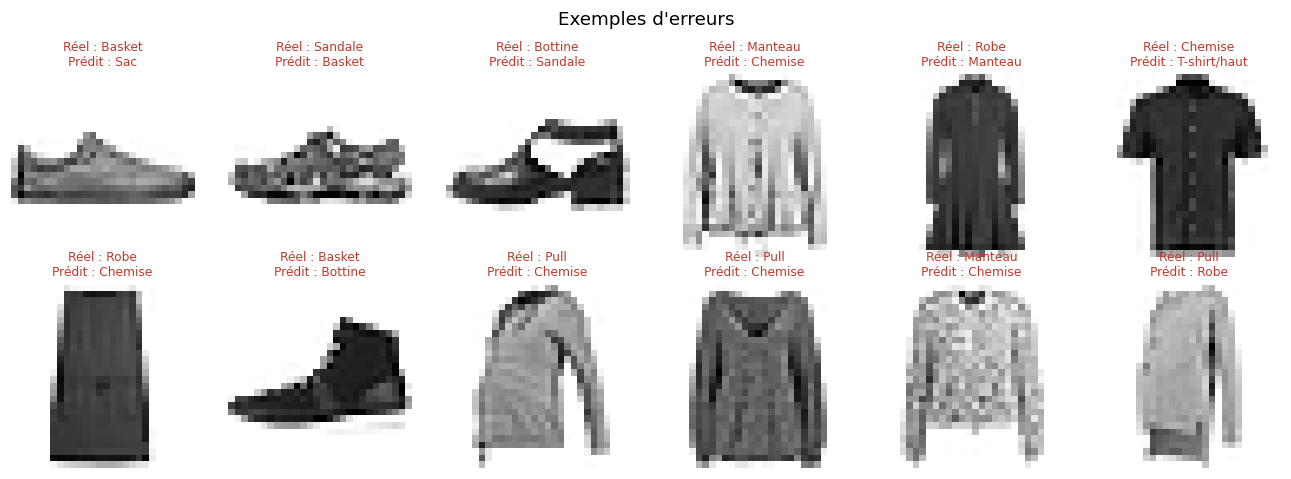

In [14]:
erreurs = torch.where(vraies != predites)[0][:12]
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, i in zip(axes.ravel(), erreurs):
    ax.imshow(toutes_images[i, 0], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"Réel : {CLASSES[vraies[i]]}\nPrédit : {CLASSES[predites[i]]}", fontsize=8, color="#c0392b")
plt.suptitle("Exemples d'erreurs"); plt.tight_layout(); plt.show()

**Discussion.** Les confusions les plus fréquentes (chemise, T-shirt, pull, manteau) sont-elles plausibles ? Un observateur humain les commettrait-il sur des images de 28 × 28 pixels ?

## 9. Exercice : un réseau plus profond

### Exercice 8 — Ajouter un troisième bloc convolutif

Ajoutez un bloc `Conv2d(32, 64) → ReLU → MaxPool2d(2)`. Après trois sous-échantillonnages, la carte passe de 7 × 7 à **3 × 3** (division entière) : l'entrée de la première couche linéaire devient `64 * 3 * 3`.

**Prédiction.** L'exactitude va-t-elle augmenter ? Et le temps par époque ?

In [ ]:
class CNNProfond(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.extracteur = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            ...   # À COMPLÉTER
        )
        self.classifieur = nn.Sequential(nn.Flatten(), nn.Linear(..., 64), nn.ReLU(), nn.Linear(64, n_classes))   # À COMPLÉTER

    def forward(self, x):
        return self.classifieur(self.extracteur(x))

torch.manual_seed(0)
profond = CNNProfond().to(appareil)
opt_profond = torch.optim.Adam(profond.parameters(), lr=1e-3)
for epoque in range(1, 4):
    debut = time.time()
    entrainer_une_epoque(profond, charge_ent, opt_profond, perte_fn)
    print(f"Époque {epoque} | exactitude test {evaluer(profond, charge_test, perte_fn)[1]:.1%} | {time.time() - debut:.0f} s")
print(f"Référence, CNN à 2 blocs : {suivi['exactitude_test'][-1]:.1%}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
class CNNProfond(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.extracteur = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifieur = nn.Sequential(nn.Flatten(), nn.Linear(64 * 3 * 3, 64), nn.ReLU(), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.classifieur(self.extracteur(x))

torch.manual_seed(0)
profond = CNNProfond().to(appareil)
opt_profond = torch.optim.Adam(profond.parameters(), lr=1e-3)
for epoque in range(1, 4):
    debut = time.time()
    entrainer_une_epoque(profond, charge_ent, opt_profond, perte_fn)
    print(f"Époque {epoque} | exactitude test {evaluer(profond, charge_test, perte_fn)[1]:.1%} | {time.time() - debut:.0f} s")
print(f"Référence, CNN à 2 blocs : {suivi['exactitude_test'][-1]:.1%}")
```

</details>

Ajouter des couches n'améliore pas automatiquement les résultats : avec trois époques, le réseau plus profond obtient un résultat comparable. Une capacité accrue demande généralement plus de données, plus d'époques ou une régularisation (notebook 4).

### Sauvegarder le modèle

In [ ]:
torch.save(modele.state_dict(), "cnn_fashion.pt")       # on sauvegarde les paramètres, pas le code
recharge = CNN(); recharge.load_state_dict(torch.load("cnn_fashion.pt", map_location="cpu"))
print("Paramètres sauvegardés puis rechargés.")

In [ ]:
quiz("Pourquoi un CNN compte-t-il beaucoup moins de paramètres qu'un réseau entièrement connecté sur une image ?",
     ["Parce qu'il réduit la résolution des images", "Parce qu'un même petit filtre est appliqué à toutes les positions (partage des poids)", "Parce qu'il n'a pas de biais"],
     1, "Un filtre 3 × 3 possède 9 poids, quel que soit le nombre de positions où il est appliqué.")

In [ ]:
quiz("Erreur « Expected all tensors to be on the same device ». Que faut-il faire ?",
     ["Réinstaller PyTorch", "Placer le modèle et chaque lot de données sur le même appareil avec .to(appareil)", "Réduire la taille des lots"],
     1, "Le modèle est déplacé une fois ; chaque lot est déplacé au moment de son utilisation.")

## À retenir

- La **convolution** applique un filtre appris à toutes les positions de l'image (connectivité locale, partage des poids).
- Le **max pooling** réduit la taille des cartes en conservant l'information essentielle.
- Un CNN empile des blocs **Conv → ReLU → Pool**, puis `Flatten` et des couches `Linear`.
- `Dataset` donne accès aux observations ; `DataLoader` produit des **mini-lots** mélangés.
- Calcul sur **GPU** : `modele.to(appareil)` une fois, `lot.to(appareil)` à chaque lot.

**Notebook suivant :** 4 — Améliorer la généralisation.